In [2]:
#pip install opencv-python

# Preprocessing

In [3]:
import numpy as np 
import matplotlib.pyplot as plt 
import cv2 

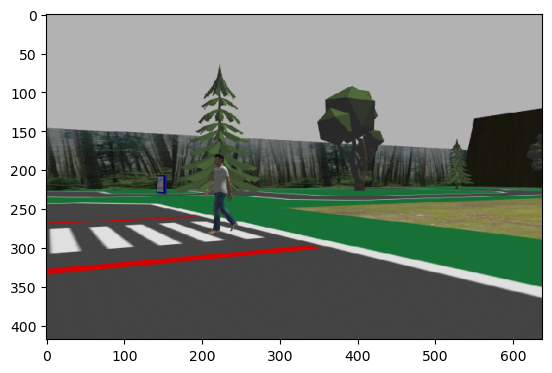

In [33]:
#img_path = "/Users/annabel/Downloads/ENPH353_competition/ENPH353_Competition/src/my_controller/my_controller/testPhotos/img.png"
img_path = "/home/fizzer/ENPH353_Competition/src/my_controller/my_controller/testPhotos/img3.png"
img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb) #sanity check 

In [34]:
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV) #convert to HSV for better colour processing 

#since red wraps around the HSV scale, we need to define lower and upper bounds for red (two ranges):
# Lower red range (0 to 10)
lower_red1 = np.array([0, 120, 70])
upper_red1 = np.array([10, 255, 255])

# Upper red range (170 to 179)
lower_red2 = np.array([170, 120, 70])
upper_red2 = np.array([179, 255, 255])

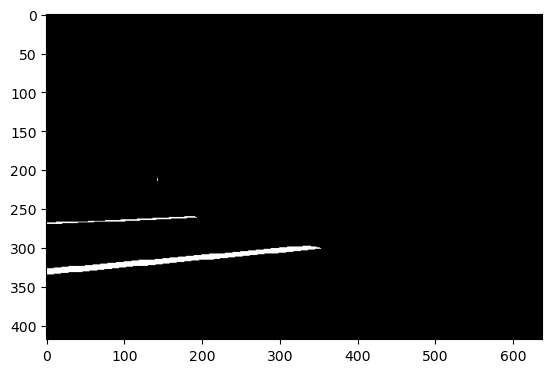

In [35]:
# 4. Create masks for both ranges and combine them
mask1 = cv2.inRange(hsv, lower_red1, upper_red1)
mask2 = cv2.inRange(hsv, lower_red2, upper_red2)
red_mask = cv2.bitwise_or(mask1, mask2)

#if you wanted to extract the red parts only: 
#result = cv2.bitwise_and(img, img, mask=red_mask)

plt.imshow(red_mask, cmap="gray")

In [36]:
contours, _ = cv2.findContours(red_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

#using cv2.contourArea excludes stripes that are 1 pixel tall so we can't use that 
def pixel_area(c, shape):
    m = np.zeros(shape, np.uint8)
    cv2.drawContours(m, [c], -1, 255, thickness=cv2.FILLED)
    return cv2.countNonZero(m)

areas = [pixel_area(c, red_mask.shape) for c in contours]
print(areas)
print(len(contours))

[2421, 386, 4]
3


# Test function 

In [44]:
#find the line of best fit for contours only if their length (across the screen) exceeds threshold val
thresholdLen = 125
maxAspectRatio = 1/5
maxSlope = 15 # degrees 

def isCrosswalkPresent(contours, red_mask):

    if len(contours) < 2:  # automatically skip if less than 2 strips detected
        return False

    # sort contours by num pixels, largest (closest) first
    contours = sorted(contours, key=lambda c: pixel_area(c, red_mask.shape), reverse=True)

    # keep only long thin strips 
    candidates = []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        print("Currently processing: ", x, y, w, h)
        if w >= thresholdLen and h <= w * maxAspectRatio:
            candidates.append((c, (x, y, w, h)))
            print("Appended: ", x, y, w, h)

    # keep only the strips whose line of best fit is near-horizontal
    flatCandidates = []
    for c, rect in candidates:
        vx, vy, _, _ = cv2.fitLine(c, cv2.DIST_L2, 0, 0.01, 0.01).flatten()
        angle = abs(np.degrees(np.arctan2(vy, vx)))
        angle = min(angle, 180 - angle)  # fitLine's direction vector can point either way
        print("Angle: ", angle)
        if angle <= maxSlope:
            flatCandidates.append(rect)

    if len(flatCandidates) < 2:  # need two near-horizontal strips
        return False

    #unpack the rectangle values from flatCandidates, taking the two largest only: 
    xClose, yClose, wClose, hClose = flatCandidates[0] 
    xFar, yFar, wFar, hFar = flatCandidates[1] 

    # validate that this is the crosswalk: the larger (closer) strip should have Xmax >= Xmax of the further strip
    # and yMax > yMax of the further strip (closer = lower in the image = larger y)
    xMaxClose, xMaxFar, yMaxClose, yMaxFar = xClose + wClose, xFar + wFar, yClose + hClose, yFar + hFar

    if (xMaxClose >= xMaxFar and yMaxClose > yMaxFar):
        return True

    return False 

    

In [45]:
print(isCrosswalkPresent(contours, red_mask))

Currently processing:  1 298 353 37
Appended:  1 298 353 37
Currently processing:  1 260 193 10
Appended:  1 260 193 10
Currently processing:  143 211 1 4
Angle:  5.16394
Angle:  2.4328918
True


# Testing with video 

In [46]:
import io, contextlib, csv

video_path = "/home/fizzer/ENPH353_Competition/src/my_controller/my_controller/testMedia/drive_to_crosswalk_v2.mp4"
cap = cv2.VideoCapture(video_path)
fps = cap.get(cv2.CAP_PROP_FPS)

results = []   # (frame index, timestamp in seconds, detected)
frame_idx = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break

    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv, lower_red1, upper_red1) | cv2.inRange(hsv, lower_red2, upper_red2)
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # isCrosswalkPresent has debug prints; silence them so 200+ frames don't flood the notebook
    with contextlib.redirect_stdout(io.StringIO()):
        present = isCrosswalkPresent(cnts, mask)

    results.append((frame_idx, round(frame_idx / fps, 3), present))
    frame_idx += 1
cap.release()

with open("crosswalk_results.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["frame", "time_s", "crosswalk_present"])
    w.writerows(results)

hits = [r for r in results if r[2]]
print(f"{len(hits)}/{len(results)} frames detected")
if hits:
    print(f"first detection: frame {hits[0][0]} at {hits[0][1]} s; last: frame {hits[-1][0]} at {hits[-1][1]} s")

5/211 frames detected
first detection: frame 111 at 7.4 s; last: frame 118 at 7.867 s


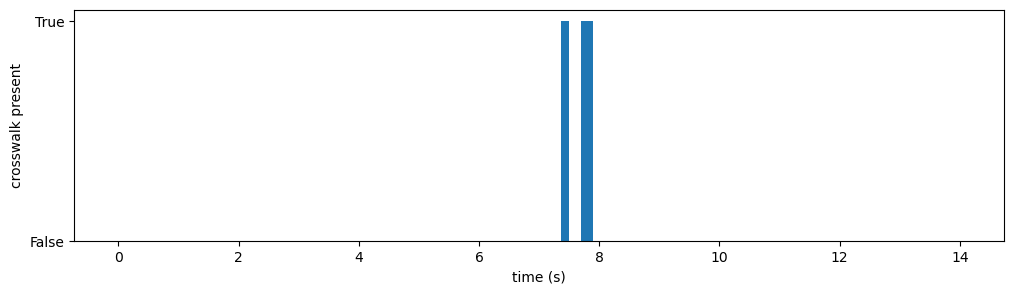

In [47]:
# plot the results: 
times, vals = [], []
with open("crosswalk_results.csv") as f:
    for row in csv.DictReader(f):
        times.append(float(row["time_s"]))
        vals.append(1 if row["crosswalk_present"] == "True" else 0)

plt.figure(figsize=(12, 3))
plt.bar(times, vals, width=1/15)   # 1/15 s = one frame at 15 fps
plt.yticks([0, 1], ["False", "True"])
plt.xlabel("time (s)")
plt.ylabel("crosswalk present")
plt.show()


In [48]:
video_path = "/home/fizzer/ENPH353_Competition/src/my_controller/my_controller/testMedia/drive_to_crosswalk_v2.mp4"
out_path   = "/home/fizzer/ENPH353_Competition/src/my_controller/my_controller/testMedia/drive_to_crosswalk_annotated.mp4"

cap = cv2.VideoCapture(video_path)
fps = cap.get(cv2.CAP_PROP_FPS)
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
out = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

frame_idx = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break

    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv, lower_red1, upper_red1) | cv2.inRange(hsv, lower_red2, upper_red2)
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    with contextlib.redirect_stdout(io.StringIO()):
        present = isCrosswalkPresent(cnts, mask)

    label = f"crosswalk: {present}   t={frame_idx / fps:.2f}s"
    color = (0, 200, 0) if present else (0, 0, 255)   # BGR: green for True, red for False
    cv2.rectangle(frame, (0, 0), (330, 32), (0, 0, 0), -1)        # dark box so the text is readable
    cv2.putText(frame, label, (8, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2, cv2.LINE_AA)

    out.write(frame)
    frame_idx += 1

cap.release()
out.release()
print("saved", out_path)

saved /home/fizzer/ENPH353_Competition/src/my_controller/my_controller/testMedia/drive_to_crosswalk_annotated.mp4


### extra stuff

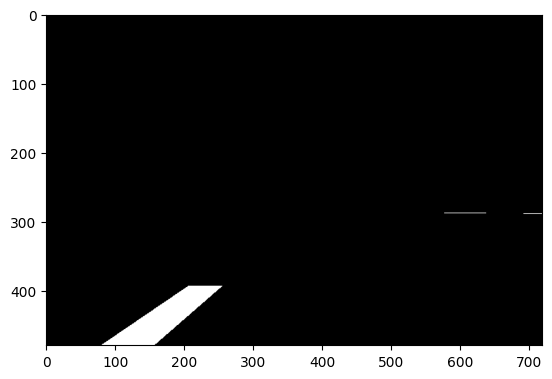

In [ ]:
gapCloseSize=25 
minLineWidth=50

closed = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, np.ones((1, gapCloseSize), np.uint8))
horiz = cv2.morphologyEx(closed, cv2.MORPH_OPEN, np.ones((1, minLineWidth), np.uint8))
plt.imshow(horiz, cmap="gray")